In [4]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [5]:
img = cv.imread(r'img.jpg', cv.IMREAD_GRAYSCALE)

In [6]:
def otsu_thresholding(img):
    
    hist = np.zeros(256)
    for i in img.flatten():
        hist[i] += 1
    total = img.size
    max_variance = 0
    threshold = 0
    
    for t in range(256):
        # Calculate weights and means for the two classes
        w0 = np.sum(hist[:t]) / total
        w1 = np.sum(hist[t:]) / total
        
        if w0 == 0 or w1 == 0:
            continue
        # Calculate means for the two classes
        mu0 = np.sum(np.arange(t) * hist[:t]) / np.sum(hist[:t])
        mu1 = np.sum(np.arange(t, 256) * hist[t:]) / np.sum(hist[t:])
        # Calculate between-class variance
        variance = w0 * w1 * (mu0 - mu1) ** 2
        
        if variance > max_variance:
            max_variance = variance
            threshold = t
        
    return threshold

(np.float64(-0.5), np.float64(553.5), np.float64(553.5), np.float64(-0.5))

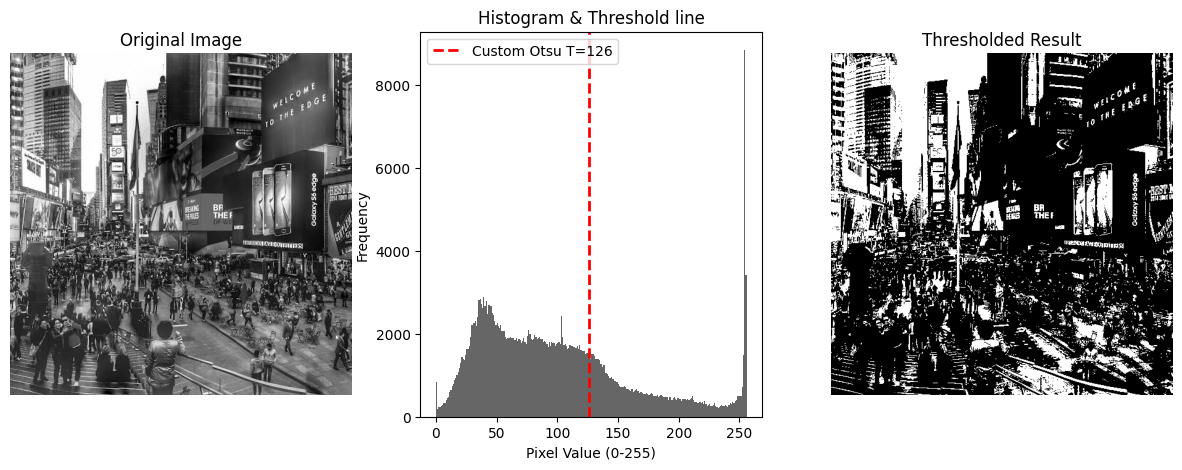

In [ ]:
thresh_val = otsu_thresholding(img)
binary_img = (img > thresh_val).astype(np.uint8) * 255
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

# Subplot 2: Histogram
plt.subplot(1, 3, 2)
plt.hist(img.flatten(), bins=256, range=(0, 256), color='black', alpha=0.6)
plt.axvline(thresh_val, color='red', linestyle='--', linewidth=2, 
            label=f'Custom Otsu T={thresh_val}')
plt.title('Histogram & Threshold line')
plt.xlabel('Pixel Value (0-255)')
plt.ylabel('Frequency')
plt.legend()

# Subplot 3: Binary Mask Result
plt.subplot(1, 3, 3)
plt.imshow(binary_img, cmap='gray')
plt.title('Thresholded Result')
plt.axis('off')